# picoRSI in one notebook

The whole loop, from scratch, in one file: a task generator, a small VLM, a reward, a GRPO step on
LoRA, and a gate. No imports from the repo, so you can read it top to bottom.

```
for each iteration:
    tasks    = sample from a fixed pool             # the model does not choose these (yet)
    attempts = the CURRENT model answers each task  # data generated on the fly, by the model itself
    rewards  = check each answer against the truth  # the verifier
    update   = one GRPO step on LoRA                # learn from its own attempts
    gate     = better on tasks it never trains on?  # keep, or undo exactly
```

Every training example is the model's own attempt, so this is **online, on-policy** learning, not
offline SFT. But the task pool, the reward and the update rule are all fixed by us: this is
**self-training with a safety gate**, not yet a self-*evolving* loop. The last section says what is missing.

The repo version (`train.py`) is the same loop plus clipping, a KL term, a curriculum, skill memory,
cost accounting and logging. Runs on one GPU in about 10 minutes; on CPU it works but is slow.

In [1]:
import copy, re, time, zlib
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image
from transformers import AutoModelForImageTextToText, AutoProcessor

torch.manual_seed(0)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
MODEL_ID = "HuggingFaceTB/SmolVLM-256M-Instruct"
print(DEVICE)

cuda


## 1. Tasks: a verifiable environment

A task is an image of 1–9 blue squares, and the question "how many?". Every task is a pure function
of its seed, so the answer is known and checkable. The seed's hash fixes which **split** it belongs
to: `train` (the loop learns from these), `gate` (only used to decide keep/undo), `heldout` (only
used to report). An image never moves between splits.

How many blue squares are there? Answer with a single digit. -> 9


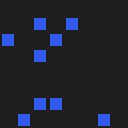

In [2]:
def split_of(seed):
    b = zlib.crc32(str(seed).encode()) % 10
    return "train" if b <= 6 else "gate" if b == 7 else "heldout"

def make_task(seed):
    rng = np.random.default_rng(seed)
    n = int(rng.integers(1, 10))
    img = np.full((64, 64, 3), 30, np.uint8)
    for cell in rng.permutation(64)[:n]:
        r, c = divmod(int(cell), 8)
        img[r*8+1:r*8+7, c*8+1:c*8+7] = (50, 90, 230)
    return {"seed": seed, "image": img, "question": "How many blue squares are there? Answer with a single digit.",
            "answer": str(n)}

def draw(split, n, rng):
    out = []
    while len(out) < n:
        s = int(rng.integers(0, 2**31 - 1))
        if split_of(s) == split:
            out.append(make_task(s))
    return out

GATE    = draw("gate", 32, np.random.default_rng(1))       # fixed: the same gate set for every decision
HELDOUT = draw("heldout", 100, np.random.default_rng(2))   # fixed, never trained on, never gated on
t = make_task(7); print(t["question"], "->", t["answer"])
Image.fromarray(t["image"]).resize((128, 128), Image.NEAREST)

## 2. The policy: a small VLM that can sample and score its own answers

Two capabilities are all RL needs: **sample** an answer, and compute **log π(answer | prompt)** under
the current weights (differentiable). We prefill `Answer:` so a 256M model replies with a number.

In [3]:
processor = AutoProcessor.from_pretrained(MODEL_ID)
processor.image_processor.do_image_splitting = False                 # one 512px tile per image
processor.image_processor.size = processor.image_processor.max_image_size = {"longest_edge": 512}
model = AutoModelForImageTextToText.from_pretrained(MODEL_ID, dtype=torch.bfloat16).to(DEVICE).eval()
model.requires_grad_(False)
tok = processor.tokenizer
NEVER = [i for i in tok.convert_tokens_to_ids(["<image>", "<fake_token_around_image>", "<global-img>"])
         if i is not None and i != tok.unk_token_id]                 # image placeholders are never an answer

def prompt_inputs(task):
    chat = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": task["question"]}]}]
    text = processor.apply_chat_template(chat, add_generation_prompt=True) + " Answer:"
    batch = processor(text=[text], images=[[Image.fromarray(task["image"])]], return_tensors="pt")
    return {k: v.to(DEVICE, torch.bfloat16) if v.is_floating_point() else v.to(DEVICE) for k, v in batch.items()}

@torch.no_grad()
def sample(task, n, greedy=False):
    # n answers to one task: token ids (for training) and text (for the reward)
    inp = prompt_inputs(task)
    out = model.generate(**inp, max_new_tokens=4, do_sample=not greedy, temperature=1.0, top_k=0, top_p=1.0,
                         num_return_sequences=1 if greedy else n, suppress_tokens=NEVER,
                         pad_token_id=tok.pad_token_id)
    comps = []
    for seq in out[:, inp["input_ids"].shape[1]:].tolist():
        if tok.eos_token_id in seq:
            seq = seq[:seq.index(tok.eos_token_id) + 1]
        comps.append(seq)
    return inp, comps, [tok.decode(c, skip_special_tokens=True) for c in comps]

def logprob(inp, completion):
    # sum of log pi(token) over the completion, with gradients when LoRA requires them
    ids = torch.tensor([completion], device=DEVICE)
    full = dict(inp, input_ids=torch.cat([inp["input_ids"], ids], 1))
    full["attention_mask"] = torch.ones_like(full["input_ids"])
    n = inp["input_ids"].shape[1]
    logits = model(**full).logits[0, n - 1:-1].float()
    return F.log_softmax(logits, -1).gather(-1, ids[0][:, None]).sum()

Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

## 3. The verifier: reward for one answer

The environment knows the truth, so the reward is exact match: 1 if the first digit is right, else 0.
This judges **one attempt**. (The gate, below, judges **one change to the model** — different job.)

In [4]:
def reward(text, task):
    m = re.search(r"\d", text)
    return float(m is not None and m.group() == task["answer"])

@torch.no_grad()
def success(tasks):
    # greedy accuracy: what the gate and the report measure
    return float(np.mean([reward(sample(t, 1, greedy=True)[2][0], t) for t in tasks]))

print("held-out success before any learning:", success(HELDOUT))

[transformers] The following generation flags are not valid and may be ignored: ['top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


held-out success before any learning: 0.35


## 4. LoRA from scratch: the part of the model that is allowed to change

A low-rank update `W x + (B A x) * alpha/r` on the attention q/v projections of the language model.
`B` starts at zero, so the model starts exactly as it was. Only `A` and `B` train, which makes a
snapshot (for the gate's undo) a few hundred KB.

In [5]:
class LoRA(nn.Module):
    def __init__(self, base, r=8, alpha=16):
        super().__init__()
        self.base, self.scale = base, alpha / r
        self.A = nn.Parameter(torch.randn(r, base.in_features, device=base.weight.device) / base.in_features**0.5)
        self.B = nn.Parameter(torch.zeros(base.out_features, r, device=base.weight.device))
    def forward(self, x):
        return self.base(x) + ((x.float() @ self.A.T @ self.B.T) * self.scale).to(x.dtype)

for name, mod in list(model.named_modules()):
    if "text_model" in name and name.endswith(("q_proj", "v_proj")):
        parent, attr = name.rsplit(".", 1)
        setattr(model.get_submodule(parent), attr, LoRA(mod))
params = [p for p in model.parameters() if p.requires_grad]
opt = torch.optim.AdamW(params, lr=1e-4)
snapshot = lambda: [p.detach().clone() for p in params]
def restore(s):
    with torch.no_grad():
        for p, v in zip(params, s): p.copy_(v)
print(sum(p.numel() for p in params), "trainable parameters")

460800 trainable parameters


## 5. One GRPO step: learn from your own attempts

For each task, sample a **group** of answers. An answer's advantage is its reward relative to the
group mean (`(r - mean) / std`), so the model is pushed toward answers that beat its own average and
away from those below it. A group where every answer scores the same carries no signal and is skipped.

This is vanilla on-policy policy gradient with a group baseline — the repo's `rsi/grpo.py` adds the
PPO-style ratio clip and a KL penalty to the starting model.

In [6]:
def grpo_step(tasks, group=8):
    opt.zero_grad()
    loss, used, rewards = 0.0, 0, []
    for t in tasks:
        inp, comps, texts = sample(t, group)                 # the data, generated now, by this model
        r = torch.tensor([reward(x, t) for x in texts])
        rewards += r.tolist()
        if r.std() == 0:                                      # all right or all wrong: nothing to compare
            continue
        adv = (r - r.mean()) / (r.std() + 1e-6)
        for a, c in zip(adv, comps):
            loss = loss - a * logprob(inp, c) / len(c)        # token-mean, like the repo
        used += len(comps)
    if used:
        (loss / used).backward()
        torch.nn.utils.clip_grad_norm_(params, 1.0)
        opt.step()
    return float(np.mean(rewards)), used

## 6. The gate: keep the change only if it helps on tasks the loop never trains on

Snapshot the LoRA weights, take the step, measure the gate split again. Not worse → keep. Worse →
restore the snapshot exactly. The gate set is fixed and disjoint from train, so the loop cannot learn
to please it directly. (The repo's gate checks four more conditions, e.g. no rise in parse failures.)

## 7. The loop

In [7]:
ITERS, TASKS_PER_ITER, GROUP = 30, 8, 8
rng = np.random.default_rng(0)
gate_score = success(GATE)
history = [(0, success(HELDOUT))]
print(f"start: gate {gate_score:.2f}  held-out {history[0][1]:.2f}")

for it in range(1, ITERS + 1):
    t0 = time.time()
    tasks = draw("train", TASKS_PER_ITER, rng)               # 1. what to practise (fixed pool, uniform)
    before = snapshot()
    train_reward, used = grpo_step(tasks, GROUP)              # 2-4. attempt, score, update
    new_score = success(GATE)                                 # 5. the gate
    kept = new_score >= gate_score and used > 0
    if kept:
        gate_score = new_score
    else:
        restore(before)
    line = f"iter {it:2d}  train reward {train_reward:.2f}  gate {new_score:.2f} -> {'keep' if kept else 'undo'}"
    if it % 10 == 0:
        history.append((it, success(HELDOUT)))
        line += f"  | held-out {history[-1][1]:.2f}"
    print(line, f"({time.time() - t0:.0f}s)")

start: gate 0.22  held-out 0.35


iter  1  train reward 0.36  gate 0.22 -> keep (11s)


iter  2  train reward 0.28  gate 0.25 -> keep (11s)


iter  3  train reward 0.30  gate 0.28 -> keep (11s)


iter  4  train reward 0.08  gate 0.28 -> keep (10s)


...

iter 26  train reward 0.66  gate 0.66 -> keep (10s)


iter 27  train reward 0.55  gate 0.62 -> undo (12s)


iter 28  train reward 0.53  gate 0.62 -> undo (14s)


iter 29  train reward 0.34  gate 0.69 -> keep (11s)


iter 30  train reward 0.66  gate 0.66 -> undo  | held-out 0.58 (33s)


In [8]:
print("held-out success:", " -> ".join(f"it{i}: {s:.2f}" for i, s in history))

held-out success: it0: 0.35 -> it10: 0.42 -> it20: 0.56 -> it30: 0.58


## 8. So is this self-evolving?

Not yet, and it is worth being precise about why.

| | this loop | a self-evolving loop |
|---|---|---|
| training data | ✅ generated by the model, on the fly | same |
| what to practise | ❌ fixed pool, uniform (repo: a frontier curriculum picks *which* pool tasks) | the model proposes tasks, e.g. harder variants of what it just mastered |
| how to improve | ❌ always one GRPO step | it chooses: weights, memory notes, prompt/scaffold edits, tools |
| what counts as good | ❌ our verifier, fixed | it improves its own judge — checked against ground truth where available |
| safety | ✅ the gate keeps or undoes every change | same — more important, the more it can change |

What is here is the **outer shell** every such system needs — on-policy data, a verifier, a reversible
update, a held-out gate — and the loop is on-policy RL post-training with that gate. The pieces that
would make it *self*-evolving are a **planner** that reads failures and picks what and how to learn
next, and **self-written tasks**. In the repo those slot in as `rsi/planner.py` and an env that accepts
proposed tasks, with the gate unchanged as the referee.